# Learned feature matching: DISK + LightGlue vs SIFT

Every multi-view pipeline (VO, SfM, relocalisation, loop closure) starts with
correspondences. This notebook compares the classical pipeline, **SIFT** + Lowe's ratio
test, with a modern learned one, **DISK** keypoints and descriptors matched by
**LightGlue**, an attention-based matcher, on two kinds of real data with pose ground truth:

* **TUM RGB-D `fr1_desk`**: handheld Kinect video, 640x480, strong motion blur, mocap poses;
* **COLMAP South Building**: 128 outdoor photos (downscaled to 1024x768) with the reference
  COLMAP model shipped with the dataset as pseudo ground truth.

**What you will learn**

* how detect–describe–match pipelines differ (hand-crafted gradients vs learned features,
  ratio test vs context-aware matching with self/cross-attention);
* how to evaluate matchers *downstream*: the relative pose from 5-point + MAGSAC++ and its
  error against ground truth (pose AUC), not just the number of matches;
* runtime and VRAM of the learned pipeline on an 8 GB laptop GPU.

**Licences:** DISK weights (`kornia/disk`, MIT/Apache-2.0) and LightGlue weights
(`kornia/lightglue`, Apache-2.0) are permissive. SuperPoint is deliberately *not* used: its
weights are under a non-commercial licence.

**Prerequisites:** notebook 01. **Data/weights:** `make data-09_multiview_geometry`.
**Runtime:** about 2 minutes (GPU for DISK/LightGlue, CPU for SIFT).

## Setup

In [1]:
# --- Setup: imports, seeding, device, data paths, plotting style ---
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cvlab.device
from cvlab import viz
from cvlab.io import data_dir, project_dir, read_image, save_json
from cvlab.tum import load_sequence

PROJECT = "09_multiview_geometry"
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import mvgeo as M  # noqa: E402

device = cvlab.device.setup(seed=0)
viz.set_style()
RESULTS_DIR = project_dir(PROJECT) / "results"

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)


## 1. Two matching pipelines

**SIFT** (Lowe 2004) detects blobs as extrema of a difference-of-Gaussians scale space,
assigns an orientation and describes a 16x16 patch with gradient histograms (128-D). We use
RootSIFT (L1-normalise, then square root), nearest-neighbour matching with the **ratio
test** $\lVert d_1 - d_{nn}\rVert < 0.8\,\lVert d_1 - d_{2nd}\rVert$ and a mutual check.

**DISK** (Tyszkiewicz et al. 2020) is a U-Net that outputs a keypoint heatmap and dense
128-D descriptors. It is trained with reinforcement learning to maximise the number of
correct matches. Its keypoints come from non-maximum suppression on the heatmap, so they
lie on the **integer pixel grid** (no sub-pixel refinement).

**LightGlue** (Lindenberger et al. 2023) matches two *sets* of features jointly: 9 layers of
self-attention (within an image) and cross-attention (between images), with rotary
positional encoding of keypoint locations, then a soft partial assignment with a
"matchability" score per point. It stops early on easy pairs and prunes unmatchable points,
so its cost adapts to difficulty.

We also run **DISK + mutual nearest neighbour** (no LightGlue) to separate the
contribution of the features from that of the matcher. Both DISK variants use 2048
keypoints per image; SIFT keeps up to 4096 (its usual operating point).

In [2]:
# --- Load the models (weights cached in weights/torch_hub by the download script) ---
dl = M.DiskLightGlue(device=device, max_keypoints=2048, fp16=True)
n_params = sum(p.numel() for p in dl.disk.parameters()) / 1e6, sum(p.numel() for p in dl.lightglue.parameters()) / 1e6
print(f"DISK {n_params[0]:.2f} M params | LightGlue {n_params[1]:.2f} M params | device {dl.device} | fp16 {dl.fp16}")

DISK 1.09 M params | LightGlue 11.88 M params | device cuda | fp16 True


## 2. Evaluation pairs with ground-truth poses

* **TUM `fr1_desk`**: frame pairs $(i, i+g)$, $g \in \{5, 10, 20, 30\}$, every 40 frames;
  pairs with less than 2 cm of GT translation are skipped (translation direction undefined).
  Intrinsics and distortion are the published Kinect calibration.
* **South Building**: image pairs $(i, i+g)$, $g \in \{1, 2, 4, 8\}$, every 8 images. The
  reference poses and the shared SIMPLE_RADIAL camera come from the COLMAP model in the
  dataset (built from the full-resolution images); intrinsics are scaled to 1024 px.

For every pair and method: matches → undistorted, normalised coordinates → 5-point +
MAGSAC++ (1 px threshold) → `recoverPose` → rotation error and translation-direction error
against GT.

In [3]:
# --- Build the two pair lists with GT relative poses ---
seq = load_sequence(data_dir("tum", "fr1_desk", "rgbd_dataset_freiburg1_desk"))
tum_pairs = []
for gap in (5, 10, 20, 30):
    for i in range(0, len(seq) - gap, 40):
        R, t = M.relative_pose_from_c2w(seq.gt_poses[i], seq.gt_poses[i + gap])
        if np.linalg.norm(t) >= 0.02:
            tum_pairs.append({"dataset": "TUM fr1_desk", "gap": gap, "a": i, "b": i + gap, "R": R, "t": t})

ref = M.load_reference_cameras(scale_to_width=1024)  # name -> T_wc, K, params (SIMPLE_RADIAL)
sb_names = sorted(ref)
sb_dir = M.south_building_dir() / "images"
sb_K = ref[sb_names[0]]["K_cv"]  # OpenCV pixel convention (COLMAP's K has c shifted by +0.5)
sb_dist = np.array([ref[sb_names[0]]["params"][3], 0.0, 0.0, 0.0])  # f, cx, cy, k -> OpenCV k1
sb_pairs = []
for gap in (1, 2, 4, 8):
    for i in range(0, len(sb_names) - gap, 8):
        R, t = M.relative_pose_from_c2w(ref[sb_names[i]]["T_wc"], ref[sb_names[i + gap]]["T_wc"])
        sb_pairs.append({"dataset": "South Building", "gap": gap, "a": i, "b": i + gap, "R": R, "t": t})
print(f"TUM pairs: {len(tum_pairs)} | South Building pairs: {len(sb_pairs)} | "
      f"South Building K:\n{sb_K.round(2)}\nradial k1 = {sb_dist[0]:.4f}")

TUM pairs: 56 | South Building pairs: 63 | South Building K:
[[853.23   0.   511.5 ]
 [  0.   853.23 383.5 ]
 [  0.     0.     1.  ]]
radial k1 = -0.0205


## 3. Run the three matchers

Times are wall-clock per pair and include feature extraction for *both* images plus
matching (GPU timings are bracketed with `torch.cuda.synchronize()`). The GPU is warmed up
first. Peak VRAM is measured over the whole DISK/LightGlue loop.

In [4]:
# --- Match every pair with SIFT, DISK+MNN and DISK+LightGlue; estimate the pose ---
METHODS = ["SIFT + ratio", "DISK + MNN", "DISK + LightGlue"]

def load_pair(p):
    if p["dataset"] == "TUM fr1_desk":
        return seq.rgb(p["a"]), seq.rgb(p["b"]), seq.camera.K, seq.dist
    return (read_image(sb_dir / sb_names[p["a"]]), read_image(sb_dir / sb_names[p["b"]]),
            sb_K, sb_dist)

warm = load_pair(sb_pairs[0])
for _ in range(3):
    dl.match(warm[0], warm[1])  # warm-up: cuDNN autotuning, CUDA context

# Candidate pairs for the match visualisation below (TUM gap 20, South Building gap 4);
# after the loop we show the candidate with the *median* LightGlue inlier count.
EX_GAP = {"TUM fr1_desk": 20, "South Building": 4}
rows, examples = [], {}
with cvlab.device.track_vram() as mem:
    for p in tum_pairs + sb_pairs:
        img1, img2, K, dist = load_pair(p)
        for name in METHODS:
            if name == "SIFT + ratio":
                m = M.sift_match(img1, img2, n_features=4096)
            else:
                m = dl.match(img1, img2, matcher="lightglue" if "LightGlue" in name else "mnn")
            est = M.ransac_essential(m, K, thresh_px=1.0, dist1=dist)
            er, et = (M.pose_errors(est["R"], est["t"], p["R"], p["t"]) if est["R"] is not None
                      else (180.0, 180.0))
            rows.append({"dataset": p["dataset"], "gap": p["gap"], "pair": f"{p['a']}-{p['b']}",
                         "method": name, "kpts": 0.5 * (m.n_kpts1 + m.n_kpts2), "matches": len(m),
                         "inliers": est["n_inliers"], "inlier_ratio": est["inlier_ratio"],
                         "rot_err": er, "t_err": et, "max_err": max(er, et), "time_ms": m.time_ms})
            if p["gap"] == EX_GAP[p["dataset"]]:
                examples[(p["dataset"], f"{p['a']}-{p['b']}", name)] = (img1, img2, m, est)
peak_vram = mem.peak_mb
df = pd.DataFrame(rows)
print(f"{len(df)} pair x method evaluations | peak VRAM (DISK + LightGlue, fp16): {peak_vram:.0f} MiB")

357 pair x method evaluations | peak VRAM (DISK + LightGlue, fp16): 1216 MiB


## 4. What the matches look like

Green lines are MAGSAC++ inliers, orange lines outliers (a random subset of at most 150
lines per pair). To avoid cherry-picking, each row shows the pair whose DISK + LightGlue
inlier count is the *median* of its group: TUM pairs 20 frames apart (strong motion blur)
and South Building pairs four images apart along the walk.

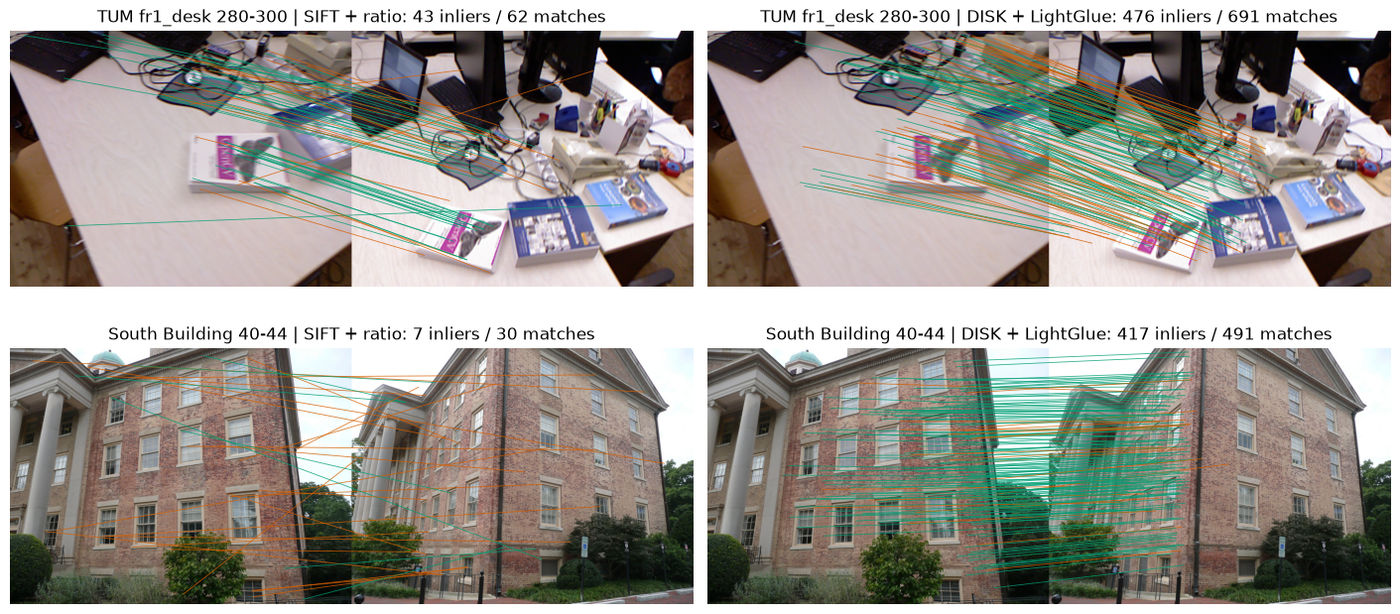

In [5]:
# --- Visualise matches for a representative pair per dataset (SIFT vs DISK + LightGlue) ---
fig, axes = plt.subplots(2, 2, figsize=(14, 6.4))
for r, ds in enumerate(["TUM fr1_desk", "South Building"]):
    cand = df[(df.dataset == ds) & (df.gap == EX_GAP[ds]) & (df.method == "DISK + LightGlue")]
    cand = cand.sort_values("inliers").reset_index(drop=True)
    pair = cand.loc[(len(cand) - 1) // 2, "pair"]  # median inlier count (lower middle)
    for c, name in enumerate(["SIFT + ratio", "DISK + LightGlue"]):
        img1, img2, m, est = examples[(ds, pair, name)]
        inl = est.get("inliers", np.zeros(len(m), bool))
        M.draw_matches(axes[r, c], img1, img2, m.x1, m.x2, inl)
        axes[r, c].set_title(f"{ds} {pair} | {name}: {est['n_inliers']} inliers / {len(m)} matches")
viz.savefig(fig, PROJECT, "matches_sift_vs_lightglue")
plt.show()

## Results

Per dataset and method: pose AUC at 5°/10°/20° over all pairs (error = max of rotation and
translation-direction error), median matches/inliers, median inlier ratio and mean time
per pair. Measured on an RTX 5060 Laptop GPU (8 GB) for DISK/LightGlue and the Intel Core
Ultra 9 275HX CPU for SIFT.

In [6]:
# --- Aggregate: AUC, match statistics, runtime per dataset and method ---
agg = []
for (ds, name), d in df.groupby(["dataset", "method"], sort=False):
    agg.append({"dataset": ds, "method": name, **{k: 100 * v for k, v in M.pose_auc(d.max_err).items()},
                "median matches": d.matches.median(), "median inliers": d.inliers.median(),
                "median inlier ratio": d.inlier_ratio.median(),
                "median rot err [deg]": d.rot_err.median(), "median t err [deg]": d.t_err.median(),
                "time per pair [ms]": d.time_ms.mean(),
                "device": "CPU" if name.startswith("SIFT") else "GPU fp16"})
agg_df = pd.DataFrame(agg)
by_gap = df.groupby(["dataset", "gap", "method"], sort=False).agg(
    inliers=("inliers", "median"), auc10=("max_err", lambda e: 100 * M.pose_auc(e)["auc@10"])).reset_index()
save_json({"per_pair": rows, "summary": agg, "by_gap": by_gap.to_dict("records"),
           "peak_vram_mb": peak_vram}, RESULTS_DIR / "nb03_matching.json")
agg_df.round(2)

,dataset,method,auc@5,auc@10,auc@20,median matches,median inliers,median inlier ratio,median rot err [deg],median t err [deg],time per pair [ms],device
0,TUM fr1_desk,SIFT + ratio,18.53,38.30,59.16,107.0,63.0,0.67,1.64,6.40,49.94,CPU
1,TUM fr1_desk,DISK + MNN,15.80,36.33,59.13,872.5,493.5,0.51,1.71,6.02,42.37,GPU fp16
2,TUM fr1_desk,DISK + LightGlue,32.25,54.02,69.78,993.0,677.5,0.70,1.07,3.85,56.95,GPU fp16
3,South Building,SIFT + ratio,57.51,66.81,72.91,196.0,130.0,0.71,0.53,1.12,167.25,CPU
4,South Building,DISK + MNN,55.91,69.20,76.67,823.0,545.0,0.70,0.60,1.35,109.18,GPU fp16
5,South Building,DISK + LightGlue,77.26,83.87,87.92,739.0,631.0,0.94,0.30,0.47,117.40,GPU fp16


Averages hide the most important effect: how each matcher degrades as the viewpoint change
grows. Below, the median number of MAGSAC++ inliers and the pose AUC@10 per frame/image gap,
and the runtime per pair.

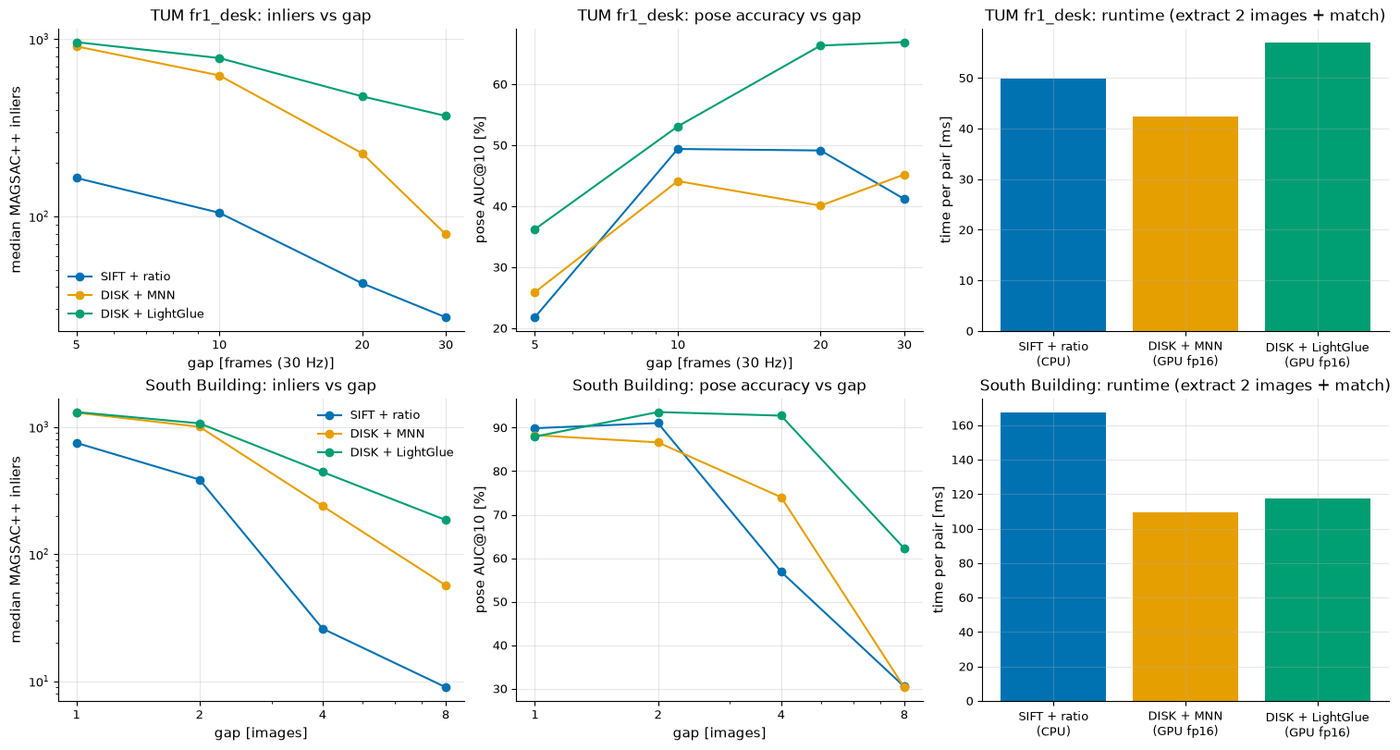

In [7]:
# --- Figures: inliers and AUC@10 vs frame gap, runtime ---
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for r, ds in enumerate(["TUM fr1_desk", "South Building"]):
    for k, name in enumerate(METHODS):
        d = by_gap[(by_gap.dataset == ds) & (by_gap.method == name)]
        ax[r, 0].plot(d.gap, d.inliers, "o-", label=name, color=viz.color(k, unit=True))
        ax[r, 1].plot(d.gap, d.auc10, "o-", label=name, color=viz.color(k, unit=True))
    unit = "frames (30 Hz)" if ds.startswith("TUM") else "images"
    ax[r, 0].set(xscale="log", yscale="log", xlabel=f"gap [{unit}]", ylabel="median MAGSAC++ inliers",
                 title=f"{ds}: inliers vs gap")
    ax[r, 1].set(xscale="log", xlabel=f"gap [{unit}]", ylabel="pose AUC@10 [%]",
                 title=f"{ds}: pose accuracy vs gap")
    for a in ax[r, :2]:
        a.set_xticks(sorted(by_gap[by_gap.dataset == ds].gap.unique()))
        a.get_xaxis().set_major_formatter(plt.ScalarFormatter())
        a.get_xaxis().set_minor_formatter(plt.NullFormatter())  # no "6x10^0" minor labels
    ax[r, 0].legend()
    d = agg_df[agg_df.dataset == ds]
    ax[r, 2].bar(range(len(d)), d["time per pair [ms]"], color=[viz.color(k, unit=True) for k in range(len(d))])
    ax[r, 2].set_xticks(range(len(d)), [f"{n}\n({dev})" for n, dev in zip(d.method, d.device)])
    ax[r, 2].set(ylabel="time per pair [ms]", title=f"{ds}: runtime (extract 2 images + match)")
viz.savefig(fig, PROJECT, "matching_summary")
plt.show()

**Takeaways**

* **Many more verified correspondences.** DISK + LightGlue returns several times more MAGSAC++
  inliers than SIFT at every gap, and the gap widens with the viewpoint change: SIFT's
  inlier count collapses on the widest South Building and TUM pairs, while LightGlue keeps
  hundreds (left column).
* **The matcher matters as much as the features.** With the *same* DISK features, plain
  mutual nearest neighbours give a clearly lower inlier ratio than LightGlue and lose most
  of their inliers at large gaps (table).
* **Pose accuracy is the honest metric.** On South Building pairs one or two images apart,
  all three methods are within a few AUC points (SIFT's sub-pixel keypoints are as good as
  anything when the geometry is easy; DISK's keypoints sit on the integer pixel grid). The
  learned matcher pulls ahead at gaps of 4 and 8 images. On the blurred TUM pairs, DISK +
  LightGlue has the highest AUC@10 at every gap, but absolute values stay modest: short
  baselines, motion blur and rolling shutter limit every method.
* **Cost.** Per pair (extracting both images + matching), the GPU pipeline is about as fast
  as CPU SIFT on 640x480 TUM frames and about 1.4 times as fast on 1024x768 South Building
  images. Most of the GPU time is DISK extraction (compare DISK + MNN); LightGlue itself
  adds only about 8-15 ms per pair. In a real system each image is extracted once and
  reused for many pairs. Peak VRAM stayed far below the 8 GB of the laptop GPU (printed
  above).
* More matches are not automatically better: notebook 04 shows LightGlue's confident
  matches between *look-alike* facades breaking an SfM reconstruction.

## Exercises

Solutions: `projects/09_multiview_geometry/solutions/solutions_03.py` (GPU).

**Exercise 1: keypoint budget.** Re-run DISK + LightGlue on the South Building gap-4 pairs with
`max_keypoints` in {512, 1024, 2048, 4096}. Plot pose AUC@10 against time per pair. Where is
the knee of the curve?

In [8]:
# --- Exercise 1: accuracy vs keypoint budget (TODO) ---
# TODO: for n in (512, 1024, 2048, 4096): dl_n = M.DiskLightGlue(device, max_keypoints=n); ...

**Exercise 2: adaptive depth and width.** LightGlue stops early when its per-point confidence
is high (`depth_confidence`) and prunes unmatchable points (`width_confidence`). Construct
`kornia.feature.LightGlue("disk", depth_confidence=-1, width_confidence=-1)` to disable both,
and compare runtime and AUC on easy (gap 1) vs hard (gap 8) South Building pairs.

In [9]:
# --- Exercise 2: LightGlue with and without adaptive computation (TODO) ---
# TODO: swap dl.lightglue for the non-adaptive variant and time dl.match on both pair sets.

**Exercise 3: RANSAC threshold vs keypoint precision.** Evaluate both SIFT and DISK +
LightGlue with MAGSAC++ thresholds of 0.5, 1 and 2 px. Which method prefers the larger
threshold, and how does that relate to DISK's integer-pixel keypoints?

In [10]:
# --- Exercise 3: sensitivity to the RANSAC threshold (TODO) ---
# TODO: M.ransac_essential(m, K, thresh_px=thr, dist1=dist) for thr in (0.5, 1.0, 2.0).